# Comparison: numerical LP vs analytical criteria

We classify a 2D grid of probability vectors as classical or nonclassical
using (a) the LP solver and (b) the analytical criteria, then overlay the
decision boundaries. All computation is delegated to `src`.

In [1]:
# Make the project importable when running from the notebooks/ directory.
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.comparison.scan_2d import run2D

## Run a (small) scan

`run2D` sweeps $P_0$ and $P_1$, holding the remaining probabilities fixed,
and returns the boundary curves for the LP solver, the analytical-K
criteria, the majorization (analytical-M) criterion, and their union.
Increase `N0`/`N1` for smoother curves.

In [3]:
boundaries, boundaries_ana, boundaries_anaK, boundaries_anaM = run2D(
    N0=120, N1=120,
    indx=np.array([0, 1, 2, 3], dtype=np.int16),
    dPA=1e-10, uPA=0.9, dPB=1e-10, uPB=0.3,
    Prest=np.array([0.05, 0.05]),
    fi='../results/comparison_demo.npy',
)

100%|██████████| 120/120 [00:15<00:00,  7.85it/s]


## Overlay the decision boundaries

The thick orange curve is the (exact) LP boundary; the analytical criteria
are necessary but not sufficient, so they lie inside the LP region.

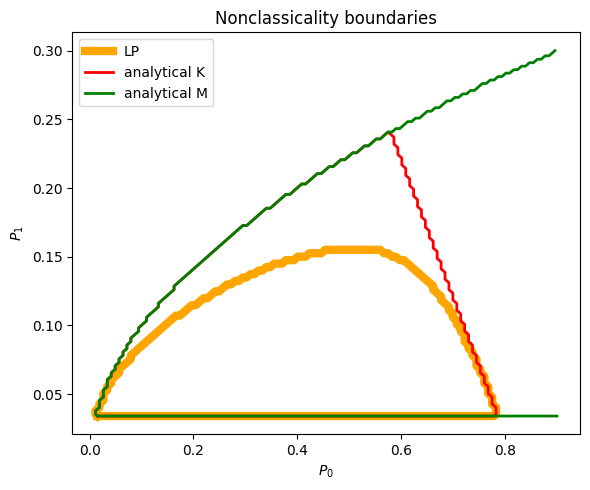

In [4]:
plt.figure(figsize=(6, 5))
for b in boundaries:
    plt.plot(b[:, 0], b[:, 1], lw=6, color='orange', label='LP')
for b in boundaries_anaK:
    plt.plot(b[:, 0], b[:, 1], lw=2, color='red', label='analytical K')
for b in boundaries_anaM:
    plt.plot(b[:, 0], b[:, 1], lw=2, color='green', label='analytical M')

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.xlabel(r'$P_0$'); plt.ylabel(r'$P_1$')
plt.title('Nonclassicality boundaries'); plt.tight_layout(); plt.show()